# Q3 Technical Report: Predicting Final Examination Marks


## 1. Objective
To predict a student's final examination marks from attendance, study hours, assignment marks and internal assessment marks using a simple linear regression model, evaluate it with regression metrics, and interpret the results.

## 2. Data and preprocessing
| Item | Detail |
|---|---|
| Records | 100 students |
| Predictors | Attendance (%), Study_Hours, Assignment_Marks, Internal_Marks |
| Target | Final_Exam_Marks (mean 71.1, std dev 10.6, range 49 to 96) |
| Cleaning | No missing values or duplicates. `Student_ID` dropped (label only). All variables numerical, no encoding needed |
| Split | 80% training (80 students), 20% testing (20 students), `random_state = 42` |

## 3. Exploratory analysis and correlation
Pearson correlation of each predictor with the final marks:

| Predictor | r | Strength |
|---|---|---|
| **Internal_Marks** | **0.599** | Moderate (strongest) |
| Assignment_Marks | 0.394 | Weak to moderate |
| Study_Hours | 0.368 | Weak to moderate |
| Attendance | 0.317 | Weak to moderate |

All relationships are positive. The predictors are almost uncorrelated with one another (all |r| below 0.12), so each adds separate information. `Internal_Marks` is selected as the single predictor for the simple linear regression.

## 4. Simple linear regression model
**Final_Exam_Marks = 46.42 + 0.364 x Internal_Marks**

| Parameter | Value | Interpretation |
|---|---|---|
| Slope (b1) | 0.364 (std error 0.053, p about 1e-9) | Each extra internal mark is associated with 0.36 more final marks |
| Intercept (b0) | 46.42 | Predicted final marks at 0 internal marks. This is outside the observed range, so it is only a mathematical anchor |

Example predictions: internal 45 gives 62.8, internal 65 gives 70.1, internal 85 gives 77.4.

## 5. Model evaluation
| Model | Dataset | MAE | MSE | RMSE | R-squared |
|---|---|---|---|---|---|
| Simple (Internal_Marks) | Training | 6.84 | 73.25 | 8.56 | 0.380 |
| Simple (Internal_Marks) | Testing | 6.57 | 63.57 | 7.97 | 0.207 |

- Predictions are off by about 6.6 marks on average (MAE) and typically by about 8 marks (RMSE).
- On all 100 students the line explains about 36% of the variance in final marks. The lower test R-squared (0.21) reflects a small test set of 20 students.

**Single-predictor comparison (same split, test set)**

| Predictor | Slope | Test MAE | Test RMSE | Test R-squared |
|---|---|---|---|---|
| Internal_Marks | 0.364 | 6.57 | 7.97 | 0.207 |
| Assignment_Marks | 0.251 | 6.19 | 8.23 | 0.155 |
| Study_Hours | 1.970 | 7.44 | 8.73 | 0.048 |
| Attendance | 0.277 | 6.89 | 8.94 | 0.003 |

Internal_Marks gives the highest R-squared, which supports using it as the main predictor.

## 6. Regression assumptions
Checked visually with residual plots (no formal hypothesis tests):

| Assumption | Check | Result |
|---|---|---|
| Linearity | Residuals vs fitted plot | No curved pattern |
| Zero-mean errors | Mean residual | 0.36, close to 0 |
| Normality of errors | Histogram and Q-Q plot of residuals | Roughly bell-shaped, points close to the line |
| Constant variance | Residuals vs fitted plot | Spread is roughly even across fitted values |
| Independence | Not plotted | Students are separate records, so errors are taken as independent |

The assumptions are reasonably met, so the simple linear regression results are valid.

## 7. Extension: multiple linear regression
Using all four predictors together:

**Final = -0.735 + 0.262 x Attendance + 2.269 x Study_Hours + 0.247 x Assignment_Marks + 0.358 x Internal_Marks**

| Predictor | Coefficient | Standardised coefficient |
|---|---|---|
| Internal_Marks | 0.358 | 0.634 |
| Study_Hours | 2.269 | 0.461 |
| Assignment_Marks | 0.247 | 0.394 |
| Attendance | 0.262 | 0.334 |

| Model | Test MAE | Test MSE | Test RMSE | Test R-squared |
|---|---|---|---|---|
| Simple (Internal_Marks) | 6.57 | 63.57 | 7.97 | 0.207 |
| **Multiple (4 predictors)** | **3.68** | **21.18** | **4.60** | **0.736** |

Adding the other three factors cuts the typical error from about 8 marks to about 4.6 and raises R-squared from 0.21 to 0.74. Internal marks remain the most influential predictor after adjusting for the others, followed by study hours.

## 8. Interpretation and conclusions
1. Internal marks are the best single predictor of final marks, but one variable leaves most of the variation unexplained.
2. Attendance, study hours and assignment marks each carry separate information. Combining all four predicts final marks well (test R-squared 0.74, RMSE about 4.6 marks).
3. In practical terms, students with strong internal results and long study hours tend to score higher in the final exam. The model can be used to identify students at risk of low final marks early in the semester.
4. The results show association, not causation.

## 9. Limitations and next steps
- The dataset is small (100 students, 20 in the test set), so metric values vary with the random split.
- Only linear relationships were modelled.
- Next steps: collect more records, validate on a new semester's data, and check for further influences such as prior grades.

## 1. Dataset selection and loading

In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.float_format", "{:.4f}".format)

CSV_DATA = """Student_ID,Attendance_%,Study_Hours,Assignment_Marks,Internal_Marks,Final_Exam_Marks
1,95,1.8,87,70,73
2,69,2,46,46,54
3,57,1.2,53,64,60
4,93,1.2,52,88,69
5,83,5.1,91,35,65
6,99,4,57,54,65
7,76,1.7,64,47,58
8,77,5.2,91,40,75
9,89,1.9,99,83,74
10,90,3.1,80,81,76
11,100,1.5,82,64,72
12,60,7,95,47,76
13,72,4.2,93,81,77
14,78,3.5,82,69,66
15,93,5.4,74,66,75
16,84,3.7,99,63,79
17,58,2.6,42,75,61
18,72,1.5,98,75,70
19,96,4.5,96,93,87
20,71,2,87,68,73
21,92,3.8,54,52,72
22,86,1.6,43,49,49
23,95,2.1,83,89,74
24,79,3.7,69,67,61
25,98,6,83,69,86
26,62,3.1,50,93,60
27,71,7.8,88,57,87
28,61,7.1,59,99,80
29,64,3.6,50,35,51
30,86,1.1,99,81,78
31,70,1.4,96,45,54
32,86,6.7,88,51,74
33,97,4.3,75,56,73
34,88,7.1,67,62,76
35,100,3.2,82,82,88
36,88,4.2,55,63,62
37,76,1.1,75,64,61
38,55,1.5,80,42,51
39,59,7.3,95,77,77
40,87,2.7,82,97,80
41,89,1.9,99,95,84
42,85,6.7,52,47,62
43,97,4,67,87,87
44,58,5.7,81,47,58
45,80,6.1,91,48,73
46,67,2.3,68,52,62
47,66,2.9,55,44,58
48,90,1.7,81,36,53
49,70,2.2,71,96,72
50,80,7.3,50,83,71
51,79,2.9,90,93,83
52,82,5.9,86,97,86
53,67,3.1,43,42,51
54,58,1.4,70,99,78
55,65,1.4,72,45,50
56,59,5.2,83,65,75
57,62,7.6,76,66,69
58,94,1.6,82,75,74
59,68,5.7,60,65,69
60,80,1.9,81,73,76
61,75,7.5,99,44,69
62,84,5.3,76,47,63
63,89,2.5,56,51,63
64,59,7.2,63,71,70
65,83,6.8,85,73,92
66,55,5.7,75,73,67
67,63,2.9,96,48,59
68,72,3,53,78,64
69,98,5.4,56,99,93
70,71,7.3,94,41,67
71,95,4,57,40,54
72,76,6.4,80,68,75
73,83,4.9,67,36,57
74,59,7.6,84,54,66
75,78,5.1,49,90,72
76,57,3.2,97,40,63
77,68,5.8,82,48,71
78,90,7.2,66,54,74
79,65,7.8,91,57,83
80,56,2.3,99,77,76
81,97,7,91,66,87
82,65,6.5,46,83,66
83,85,2.6,92,93,86
84,74,6.7,95,64,80
85,56,5.6,65,77,71
86,59,7.8,57,79,84
87,80,5.8,93,77,76
88,62,7.1,56,57,67
89,57,1.8,67,79,65
90,82,5.2,72,49,72
91,91,2.3,42,90,62
92,88,7.5,74,60,83
93,82,1.5,82,77,73
94,97,6.9,86,73,96
95,74,5.7,60,86,78
96,90,1.9,66,83,69
97,94,5,65,35,65
98,73,2.5,90,76,79
99,83,4.1,53,100,86
100,65,5.6,58,100,81
"""

df = pd.read_csv(io.StringIO(CSV_DATA))
# To load from a file instead:  df = pd.read_csv("student_performance.csv")
print("Shape:", df.shape)
df.head()

Shape: (100, 6)


,Student_ID,Attendance_%,Study_Hours,Assignment_Marks,Internal_Marks,Final_Exam_Marks
0,1,95,1.8000,87,70,73
1,2,69,2.0000,46,46,54
2,3,57,1.2000,53,64,60
3,4,93,1.2000,52,88,69
4,5,83,5.1000,91,35,65


## 2. Preprocessing

In [2]:
df = df.rename(columns={"Attendance_%": "Attendance"})

print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

# Student_ID is only a label, so it is not used as a predictor
data = df.drop(columns="Student_ID")
features = ["Attendance", "Study_Hours", "Assignment_Marks", "Internal_Marks"]
target = "Final_Exam_Marks"
data.describe().T

Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Attendance,100.0000,77.3800,13.4621,55.0000,65.0000,78.5000,89.0000,100.0000
Study_Hours,100.0000,4.2700,2.1465,1.1000,2.2750,4.0500,6.0250,7.8000
Assignment_Marks,100.0000,74.3400,16.8278,42.0000,58.7500,76.0000,88.5000,99.0000
Internal_Marks,100.0000,66.8700,18.7130,35.0000,49.0000,66.5000,81.0000,100.0000
Final_Exam_Marks,100.0000,71.1400,10.5716,49.0000,63.0000,72.0000,78.0000,96.0000


The data are complete with no duplicates. All variables are numerical, so no encoding is needed. Simple linear regression does not require scaling, so the original units are kept (this makes the coefficients easy to interpret).

## 3. Exploratory data analysis

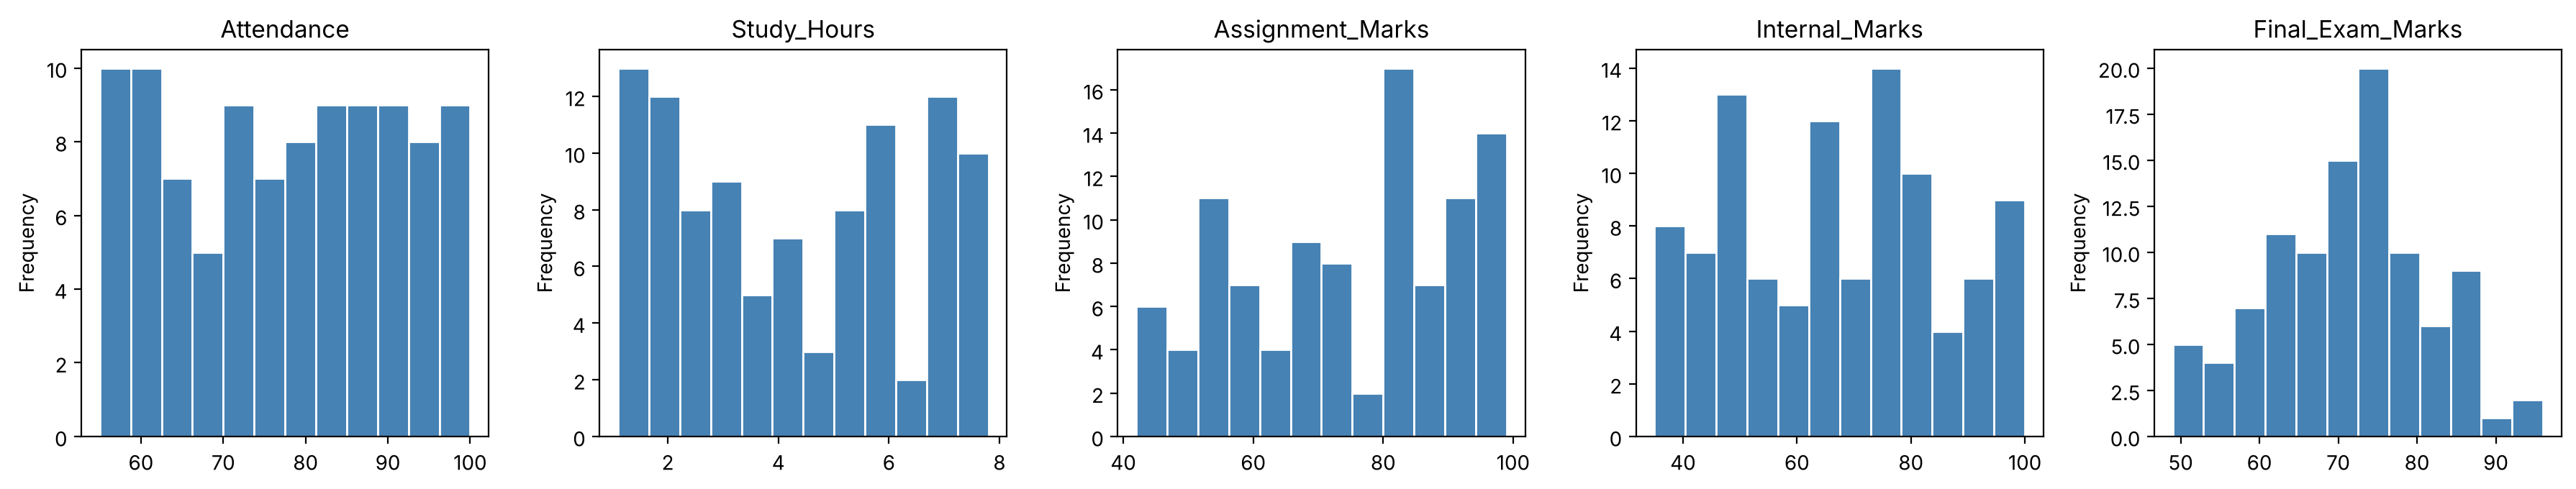

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, c in zip(axes, features + [target]):
    ax.hist(data[c], bins=12, color="steelblue", edgecolor="white")
    ax.set_title(c); ax.set_ylabel("Frequency")
plt.tight_layout(); plt.show()

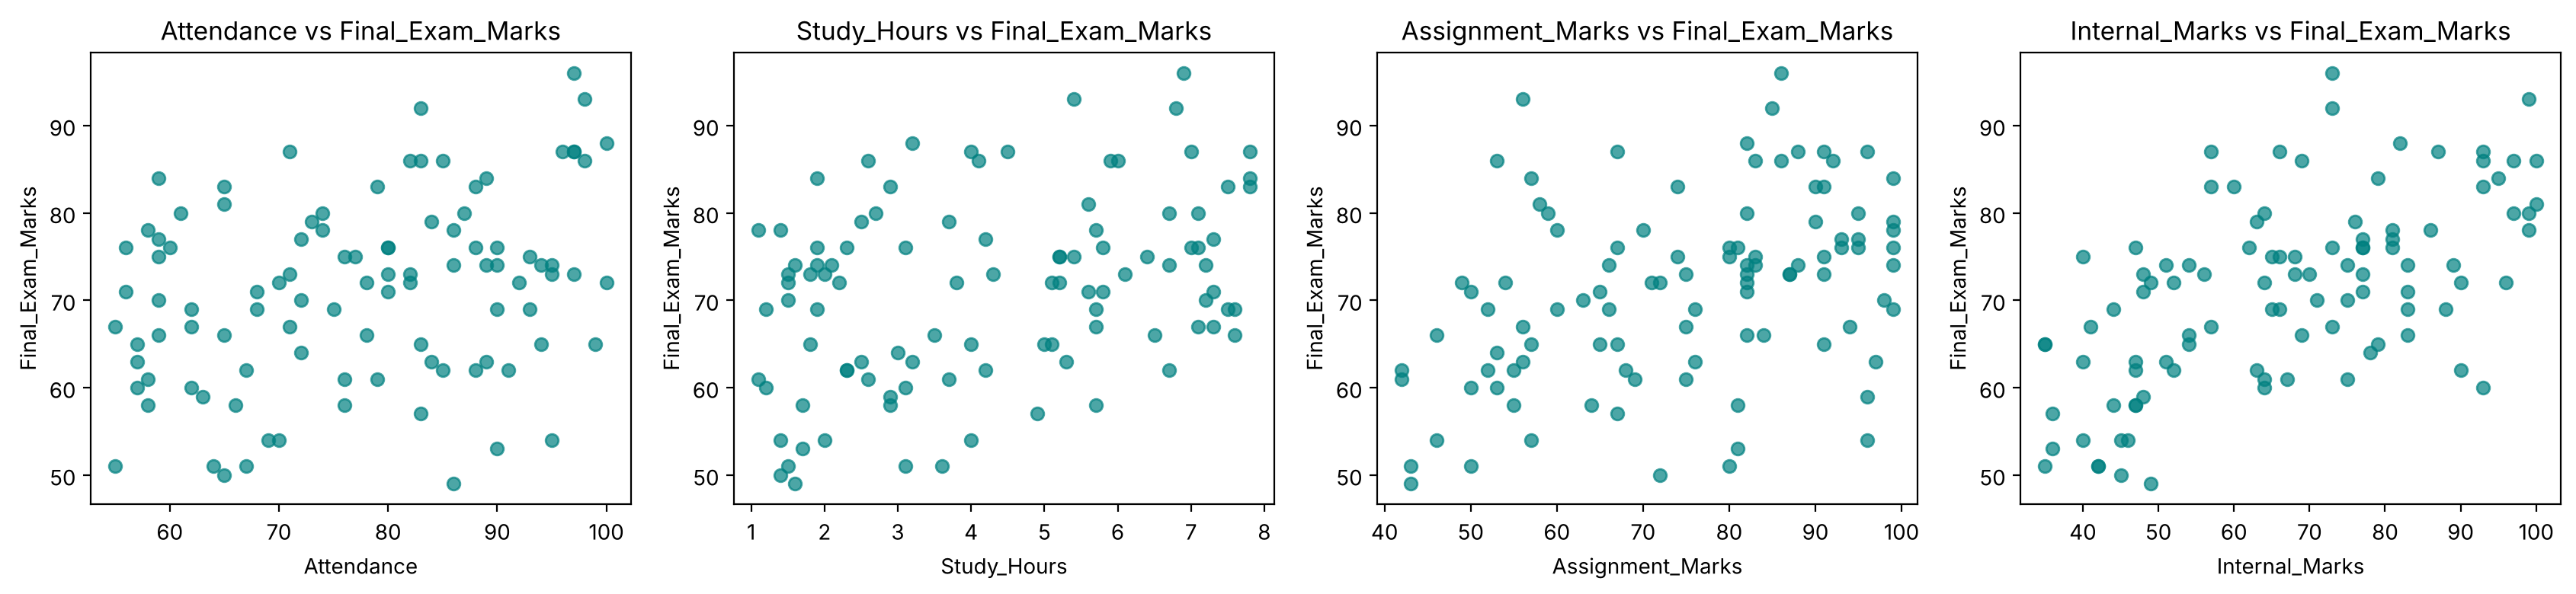

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, c in zip(axes, features):
    ax.scatter(data[c], data[target], alpha=0.7, color="teal")
    ax.set_xlabel(c); ax.set_ylabel(target); ax.set_title(f"{c} vs {target}")
plt.tight_layout(); plt.show()

## 4. Correlation analysis

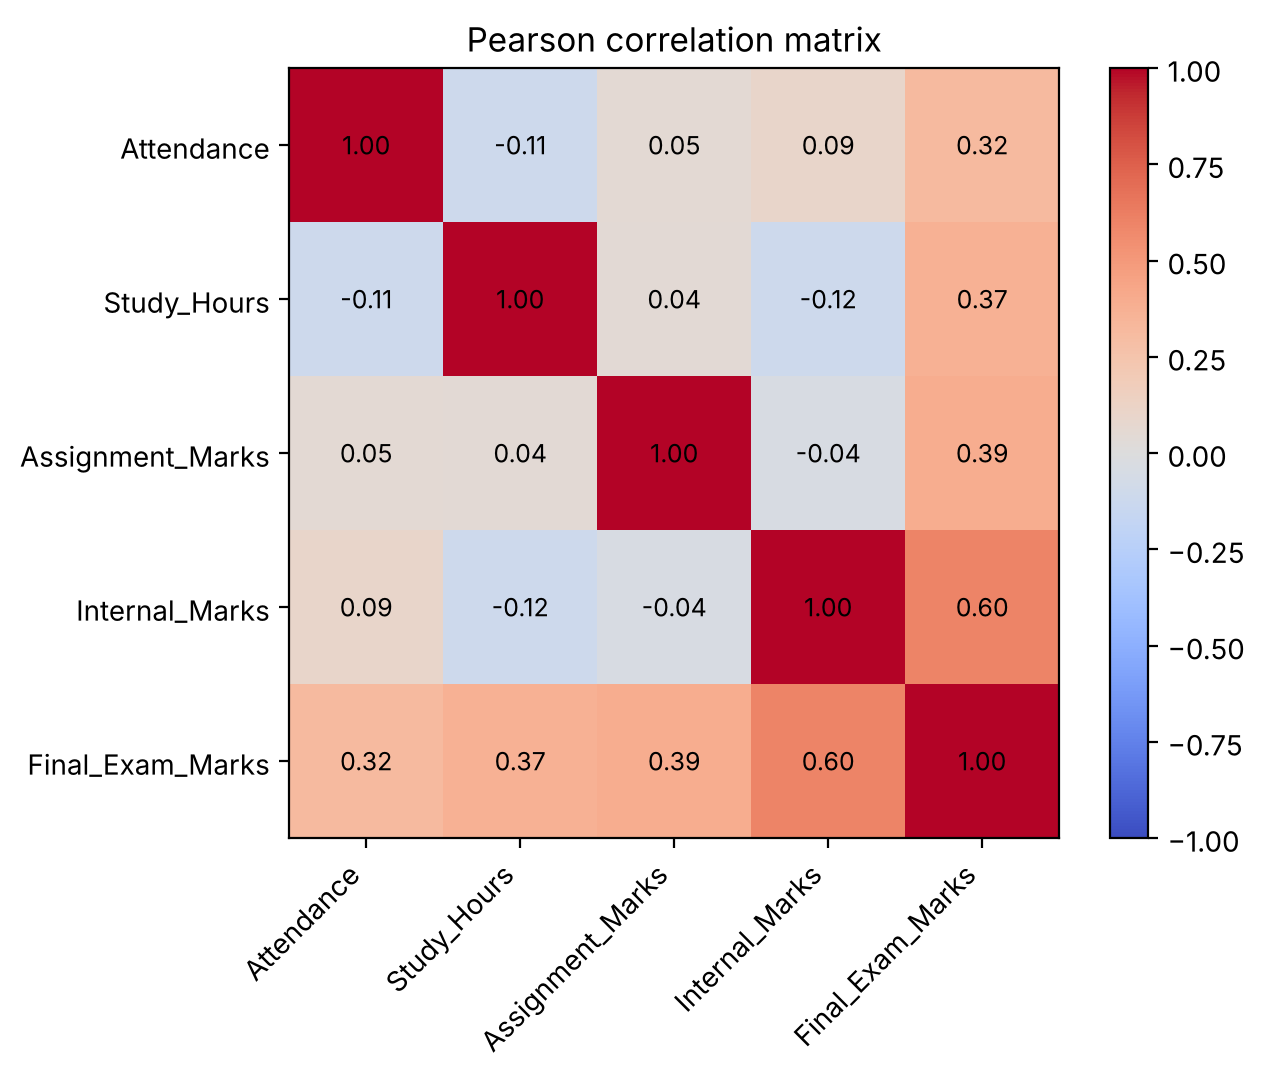

Correlation of each predictor with Final_Exam_Marks


,Pearson r
Internal_Marks,0.5989
Assignment_Marks,0.3944
Study_Hours,0.3675
Attendance,0.3167


Strongest predictor: Internal_Marks  (r = 0.599)  -> used for the simple linear regression model


In [5]:
corr = data.corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(5)); ax.set_yticks(range(5))
ax.set_xticklabels(corr.columns, rotation=45, ha="right"); ax.set_yticklabels(corr.columns)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Pearson correlation matrix"); fig.colorbar(im); plt.show()

corr_target = corr[target].drop(target).sort_values(ascending=False)
print("Correlation of each predictor with", target)
display(corr_target.to_frame("Pearson r"))

best = corr_target.abs().idxmax()
print(f"Strongest predictor: {best}  (r = {corr_target[best]:.3f})  -> used for the simple linear regression model")

The strongest linear relationship with the final marks is selected as the single predictor `X` for **simple linear regression**:  `Final = b0 + b1 * X`. The predictors are only weakly correlated with each other, which suits the multiple-regression extension in Section 9.

## 5. Train-test split

In [ ]:
X = data[[best]]          
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Training records:", len(X_train), "| Testing records:", len(X_test))

Training records: 80 | Testing records: 20


## 6. Simple linear regression model
The least-squares line minimises the sum of squared errors: slope b1 = Cov(X, Y) / Var(X) and intercept b0 = mean(Y) - b1 * mean(X).

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

b0, b1 = model.intercept_, model.coef_[0]
print(f"Regression equation:  Final_Exam_Marks = {b0:.3f} + {b1:.3f} x {best}")

# Slope significance test (on the training data)
lr = stats.linregress(X_train[best], y_train)
print(f"\nSlope = {lr.slope:.4f}, standard error = {lr.stderr:.4f}, p-value = {lr.pvalue:.2e}")
print(f"Correlation r (train) = {lr.rvalue:.4f}")

# Hand check of the formulas
b1_manual = np.cov(X_train[best], y_train, ddof=1)[0, 1] / np.var(X_train[best], ddof=1)
b0_manual = y_train.mean() - b1_manual * X_train[best].mean()
print(f"Manual check: b1 = {b1_manual:.4f}, b0 = {b0_manual:.4f}")

Regression equation:  Final_Exam_Marks = 46.421 + 0.364 x Internal_Marks

Slope = 0.3642, standard error = 0.0527, p-value = 1.18e-09
Correlation r (train) = 0.6161
Manual check: b1 = 0.3642, b0 = 46.4212


## 7. Model evaluation (MAE, MSE, RMSE, R-squared)

In [8]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

def metrics(y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    return {"MAE": mean_absolute_error(y_true, y_hat), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_hat)}

results = pd.DataFrame({"Training": metrics(y_train, y_pred_train),
                        "Testing": metrics(y_test, y_pred_test)}).T
display(results)
print(f"On average the predictions are off by about {results.loc['Testing', 'MAE']:.2f} marks (MAE).")
print(f"The model explains {results.loc['Testing', 'R2'] * 100:.1f}% of the variation in test-set final marks (R-squared).")

,MAE,MSE,RMSE,R2
Training,6.8364,73.2528,8.5588,0.3795
Testing,6.5699,63.5697,7.9731,0.2068


On average the predictions are off by about 6.57 marks (MAE).
The model explains 20.7% of the variation in test-set final marks (R-squared).


| Metric | Meaning |
|---|---|
| **MAE** | Average absolute error, in marks. Easy to interpret. |
| **MSE** | Average squared error. Penalises large errors more. |
| **RMSE** | Square root of MSE, in marks. Typical size of the error. |
| **R-squared** | Fraction of the variance in the final marks explained by the model (1 = perfect, 0 = no better than the mean). |

### Interpretation: simple linear regression

**Slope (0.364):** for every 1-mark increase in Internal_Marks, the predicted final exam marks increase by about 0.36 marks. The slope is positive, so students with higher internal marks tend to score higher in the final exam.

**Intercept (46.42):** the predicted final marks when internal marks are 0. This is outside the range of the data, so it is only the starting point of the line.

**R-squared (test 0.207):** the model explains about 20.7% of the variance in the final marks of the test students. The other 79% is due to factors that are not in this model. (The training R-squared is 0.380; the test set has only 20 students, so it is lower and less stable.)

**RMSE (test 7.97):** a typical prediction is off by about 8 marks.

## 8. Visualising the results and checking regression assumptions

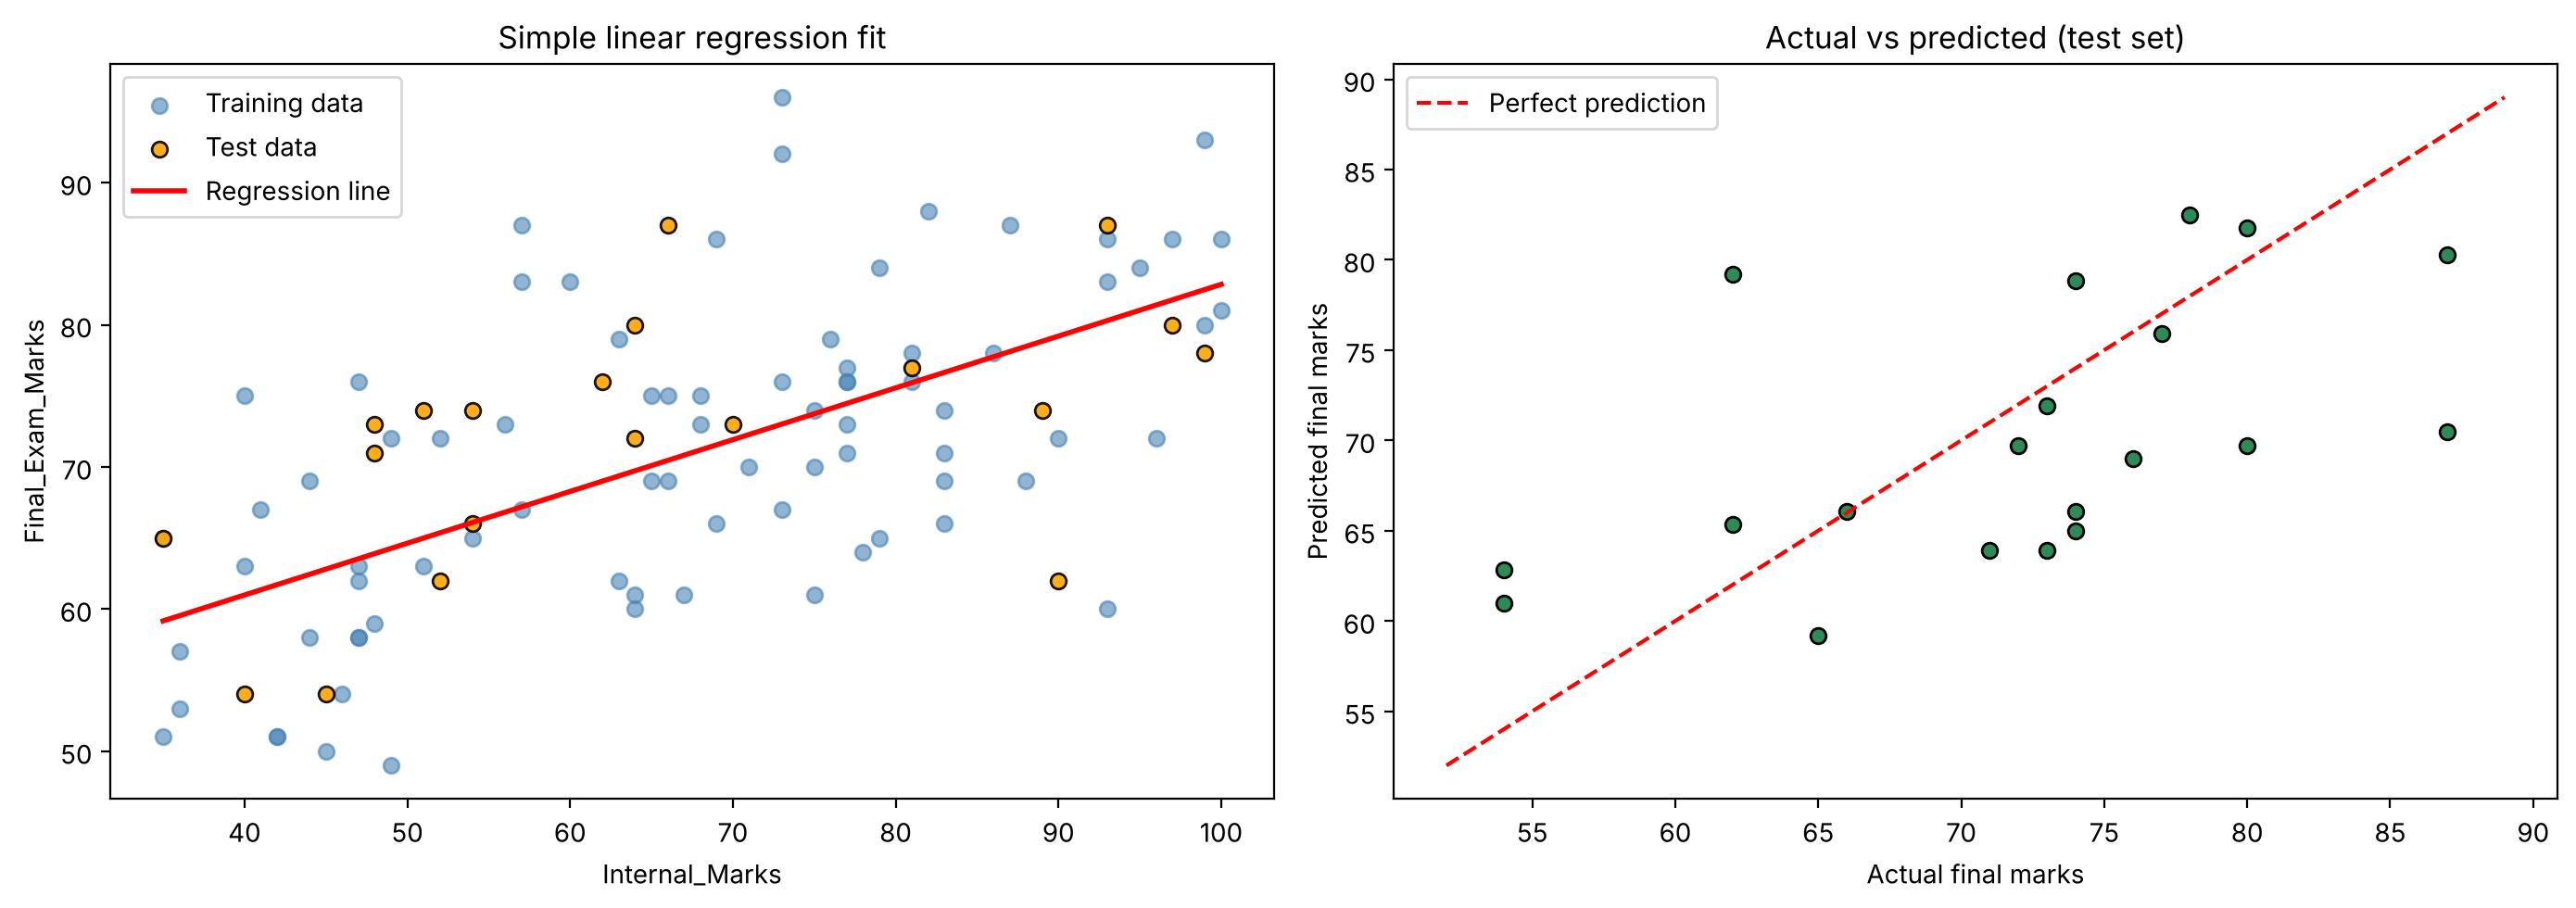

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Regression line with training and test points
axes[0].scatter(X_train, y_train, alpha=0.6, label="Training data", color="steelblue")
axes[0].scatter(X_test, y_test, alpha=0.9, label="Test data", color="orange", edgecolor="black")
xs = np.linspace(X[best].min(), X[best].max(), 100).reshape(-1, 1)
axes[0].plot(xs, model.predict(pd.DataFrame(xs, columns=[best])), color="red", lw=2, label="Regression line")
axes[0].set_xlabel(best); axes[0].set_ylabel(target); axes[0].set_title("Simple linear regression fit"); axes[0].legend()

# (b) Actual vs predicted (test set)
axes[1].scatter(y_test, y_pred_test, color="seagreen", edgecolor="black")
lims = [min(y_test.min(), y_pred_test.min()) - 2, max(y_test.max(), y_pred_test.max()) + 2]
axes[1].plot(lims, lims, "r--", label="Perfect prediction")
axes[1].set_xlabel("Actual final marks"); axes[1].set_ylabel("Predicted final marks")
axes[1].set_title("Actual vs predicted (test set)"); axes[1].legend()
plt.tight_layout(); plt.show()

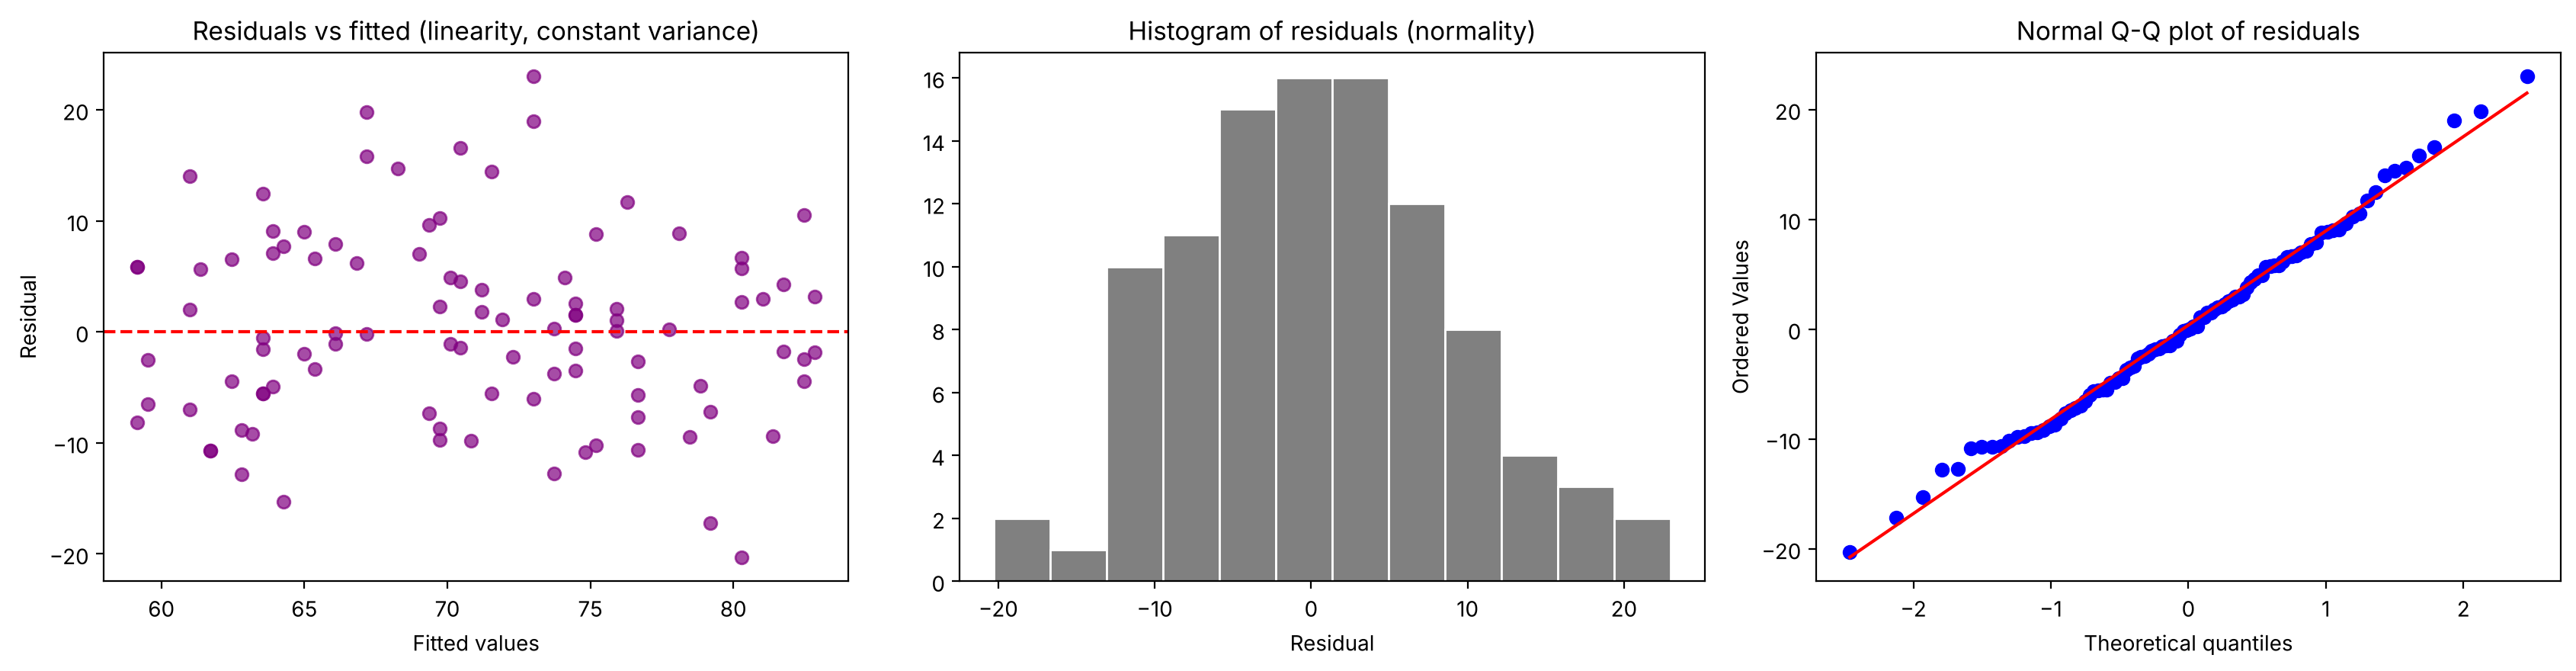

Mean of residuals: 0.3637  (should be about 0)


In [10]:
# Residual analysis using all students (fitted line from the training model)
resid = y - model.predict(X)
fitted = model.predict(X)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(fitted, resid, color="purple", alpha=0.7)
axes[0].axhline(0, color="red", ls="--")
axes[0].set_xlabel("Fitted values"); axes[0].set_ylabel("Residual"); axes[0].set_title("Residuals vs fitted (linearity, constant variance)")

axes[1].hist(resid, bins=12, color="gray", edgecolor="white")
axes[1].set_xlabel("Residual"); axes[1].set_title("Histogram of residuals (normality)")

stats.probplot(resid, dist="norm", plot=axes[2])
axes[2].set_title("Normal Q-Q plot of residuals")
plt.tight_layout(); plt.show()

print(f"Mean of residuals: {resid.mean():.4f}  (should be about 0)")

**Assumptions of linear regression:** (1) a linear relationship, (2) independent errors, (3) constant error variance (homoscedasticity), (4) normally distributed errors.

**How to read the plots above:**
- *Residuals vs fitted:* the points are scattered randomly around the zero line with no curve (linearity) and a roughly equal spread from left to right (constant variance).
- *Histogram and Q-Q plot:* the histogram is roughly bell-shaped and the Q-Q points lie close to the straight line, so the errors are approximately normal.
- *Independence:* each student is a separate record, so the errors are taken as independent.

## 9. Comparing predictors and an introduction to multiple linear regression

In [ ]:

rows = []
for f in features:
    Xtr, Xte = df.loc[X_train.index, [f]], df.loc[X_test.index, [f]]
    m = LinearRegression().fit(Xtr, y_train)
    mt = metrics(y_test, m.predict(Xte))
    rows.append([f, m.coef_[0], m.intercept_, mt["MAE"], mt["RMSE"], mt["R2"]])
compare = pd.DataFrame(rows, columns=["Predictor", "Slope", "Intercept", "Test MAE", "Test RMSE", "Test R2"]).set_index("Predictor")
display(compare.sort_values("Test R2", ascending=False))

,Slope,Intercept,Test MAE,Test RMSE,Test R2
Predictor,,,,,
Internal_Marks,0.3642,46.4212,6.5699,7.9731,0.2068
Assignment_Marks,0.2509,52.6741,6.1856,8.2319,0.1545
Study_Hours,1.9696,62.5789,7.4419,8.7335,0.0483
Attendance,0.2770,49.8626,6.8901,8.9374,0.0034


Final = -0.735 + (0.262 x Attendance) + (2.269 x Study_Hours) + (0.247 x Assignment_Marks) + (0.358 x Internal_Marks)


,Coefficient,Standardised coefficient
Attendance,0.2619,0.3335
Study_Hours,2.2690,0.4607
Assignment_Marks,0.2473,0.3937
Internal_Marks,0.3582,0.6341


,MAE,MSE,RMSE,R2
Simple (Internal_Marks),6.5699,63.5697,7.9731,0.2068
Multiple (4 predictors),3.6750,21.1799,4.6022,0.7357


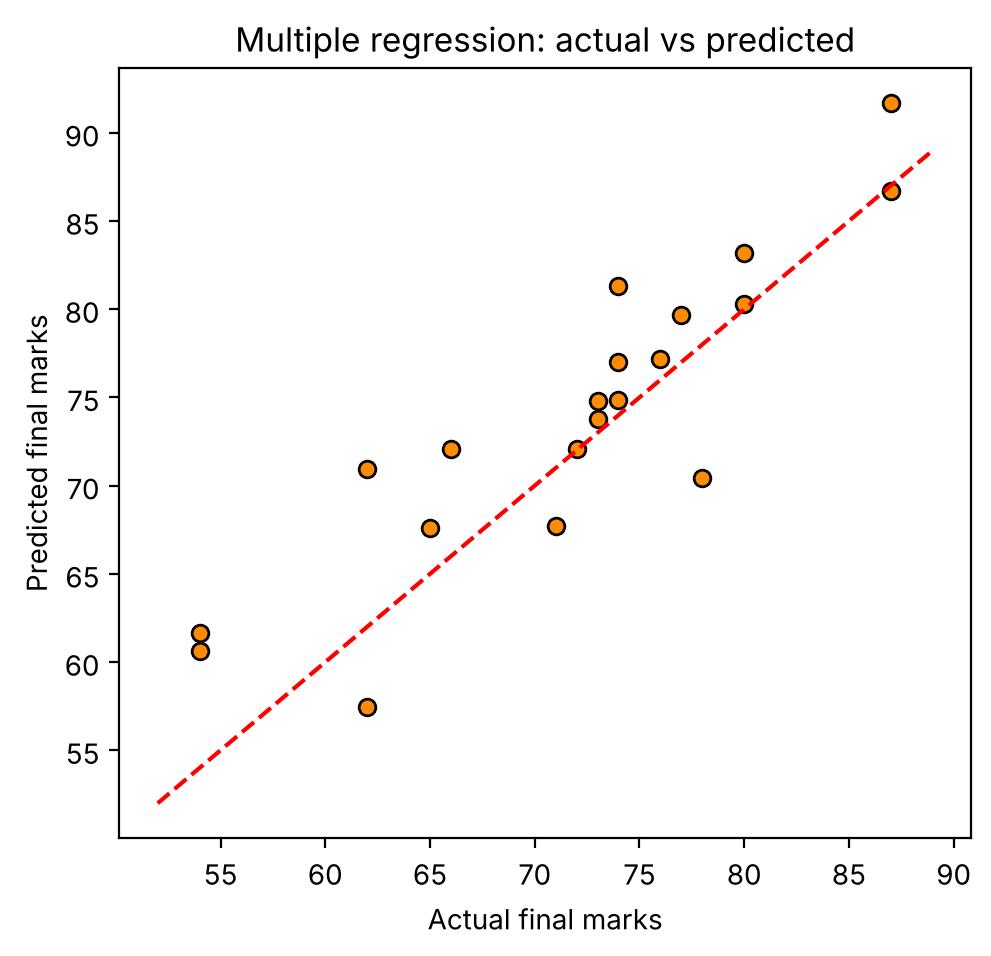

In [12]:
# (b) Multiple linear regression: all four predictors together
Xm_train, Xm_test = data.loc[X_train.index, features], data.loc[X_test.index, features]
mlr = LinearRegression().fit(Xm_train, y_train)

print("Final = {:.3f} ".format(mlr.intercept_) + " ".join(f"+ ({c:.3f} x {n})" for c, n in zip(mlr.coef_, features)))
coef_table = pd.DataFrame({"Coefficient": mlr.coef_}, index=features)
# Standardised coefficients (effect of a 1 std-dev change) allow a fair comparison between predictors
coef_table["Standardised coefficient"] = mlr.coef_ * data[features].std() / data[target].std()
display(coef_table)

mlr_test = metrics(y_test, mlr.predict(Xm_test))
final = pd.DataFrame({"Simple (" + best + ")": results.loc["Testing"], "Multiple (4 predictors)": pd.Series(mlr_test)}).T
display(final)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_test, mlr.predict(Xm_test), color="darkorange", edgecolor="black")
ax.plot(lims, lims, "r--"); ax.set_xlabel("Actual final marks"); ax.set_ylabel("Predicted final marks")
ax.set_title("Multiple regression: actual vs predicted"); plt.show()

### Interpretation: multiple linear regression

**Coefficients** (each one is the effect of that predictor while the other three are kept fixed):
- **Attendance (0.262):** each extra 1% of attendance adds about 0.26 final marks.
- **Study_Hours (2.269):** each extra hour of study adds about 2.27 final marks.
- **Assignment_Marks (0.247):** each extra assignment mark adds about 0.25 final marks.
- **Internal_Marks (0.358):** each extra internal mark adds about 0.36 final marks.

Study_Hours has the biggest raw coefficient only because it is measured in small units (hours). On the standardised scale, Internal_Marks (0.634) is the most influential, followed by Study_Hours (0.461). The intercept (-0.735) has no practical meaning on its own.

**R-squared (0.736):** the model explains about 73.6% of the variance in the final marks of the test students.

**Simple vs multiple regression (test set):**

| Model | RMSE | R-squared |
|---|---|---|
| Simple (Internal_Marks) | 7.97 | 0.207 |
| Multiple (4 predictors) | 4.60 | 0.736 |

Multiple regression is clearly better: the typical error (RMSE) falls from about 8.0 to 4.6 marks (about 42% smaller) and R-squared rises from 0.21 to 0.74. It improves because attendance, study hours and assignment marks carry information that internal marks do not, and the four predictors are almost uncorrelated with each other (all |r| below 0.12). For the same reason, the Internal_Marks coefficient barely changes (0.364 in the simple model, 0.358 here).

**Note:** the test set has only 20 students, so the metrics change somewhat with a different random split. Conclusions should rest on the overall pattern (which predictors matter and by how much) and not on small metric differences.

## 10. Using the model: example prediction

In [13]:
for marks in (45, 65, 85):
    pred = model.predict(pd.DataFrame({best: [marks]}))[0]
    print(f"{best} = {marks}  ->  predicted final exam marks = {pred:.1f}")

Internal_Marks = 45  ->  predicted final exam marks = 62.8
Internal_Marks = 65  ->  predicted final exam marks = 70.1
Internal_Marks = 85  ->  predicted final exam marks = 77.4
